In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv("../data/traffic_with_clusters.csv")

print("Shape:", df.shape)

display(df.head())

Shape: (48120, 9)


,DateTime,Junction,Vehicles,ID,hour,day_of_week,day_name,cluster,traffic_level
0,2015-11-01 00:00:00,1,15,20151101001,0,6,Sunday,1,Low Traffic
1,2015-11-01 01:00:00,1,13,20151101011,1,6,Sunday,1,Low Traffic
2,2015-11-01 02:00:00,1,10,20151101021,2,6,Sunday,1,Low Traffic
3,2015-11-01 03:00:00,1,7,20151101031,3,6,Sunday,1,Low Traffic
4,2015-11-01 04:00:00,1,9,20151101041,4,6,Sunday,1,Low Traffic


In [3]:
features = [
    "hour",
    "day_of_week",
    "cluster"
]

target = "Vehicles"

X = df[features]
y = df[target]

print("Features:")
display(X.head())

print("Target:")
display(y.head())

Features:


,hour,day_of_week,cluster
0,0,6,1
1,1,6,1
2,2,6,1
3,3,6,1
4,4,6,1


Target:


0    15
1    13
2    10
3     7
4     9
Name: Vehicles, dtype: int64

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 38496
Testing samples: 9624


In [5]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression training complete")

Linear Regression training complete


In [6]:
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R²  :", round(linear_r2, 4))

Linear Regression Results
-------------------------
MAE : 10.85
RMSE: 13.66
R²  : 0.5424


In [7]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_predictions = rf_model.predict(X_test)

print("Random Forest training complete")

Random Forest training complete


In [10]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Random Forest Results")
print("--------------------")
print("MAE :", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²  :", round(rf_r2, 4))

Random Forest Results
--------------------
MAE : 8.55
RMSE: 11.13
R²  : 0.6962


In [11]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse
    ],
    "R2": [
        linear_r2,
        rf_r2
    ]
})

display(results)

,Model,MAE,RMSE,R2
0,Linear Regression,10.848501,13.656165,0.542406
1,Random Forest,8.549791,11.126929,0.696210


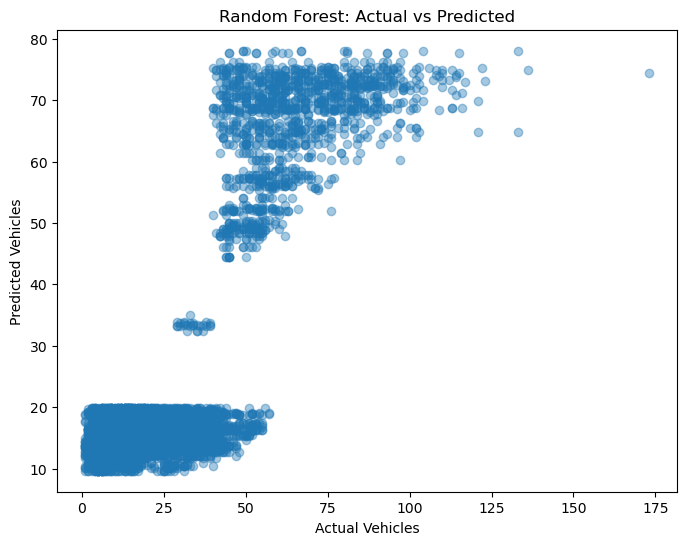

In [12]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.4
)

plt.xlabel("Actual Vehicles")
plt.ylabel("Predicted Vehicles")
plt.title("Random Forest: Actual vs Predicted")

plt.show()

In [13]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

display(importance)

,Feature,Importance
2,cluster,0.953435
0,hour,0.025804
1,day_of_week,0.020762


In [14]:
import joblib

joblib.dump(
    rf_model,
    "../data/traffic_random_forest.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [15]:
print(results)

               Model        MAE       RMSE        R2
0  Linear Regression  10.848501  13.656165  0.542406
1      Random Forest   8.549791  11.126929  0.696210
